# Global forecast with Prophet including tipo_dia as an external variable

In [22]:
import sys 
import os
from pathlib import Path
import importlib
from prefect import task
from pathlib import Path
import pandas as pd
import openpyxl
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from prophet import Prophet
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from itertools import product

ROOT = Path().cwd().parents[1]
sys.path.append(str(ROOT))


import config.settings as settings
import importlib

import warnings
warnings.filterwarnings("ignore")

## Extraer la produccion por equipos

In [23]:
df_produccion = pd.read_excel(ROOT / 'data' / 'raw' / 'SESIONES_RADIOTERAPIA_5MAY22-30ABR2026.xlsx',
                                      sheet_name = 0,
                                      engine = "openpyxl")
df_produccion.columns = df_produccion.columns.str.lower()

In [24]:
print(df_produccion.columns)

Index(['fecha', 'equipo', 'produccion', 'capacidad', 'tipo_dia', 'novedad'], dtype='object')


In [25]:
#df_produccion = pd.get_dummies(df_produccion, columns = ["novedad"])
print(df_produccion.head(5))


       fecha    equipo  produccion  capacidad tipo_dia novedad
0 2022-05-03   HALCYON          59         70  laboral     NaN
1 2022-05-03   SYNERGY          41         65  laboral     NaN
2 2022-05-03  SYNERGY2          32         47  laboral     NaN
3 2022-05-03  SYNERGY3          34         47  laboral     NaN
4 2022-05-04   HALCYON          64         70  laboral     NaN


In [26]:
df_produccion.columns = ["ds", "equipo", "y", "capacidad", "tipo_dia","novedad"]
print(df_produccion.head(3))

          ds    equipo   y  capacidad tipo_dia novedad
0 2022-05-03   HALCYON  59         70  laboral     NaN
1 2022-05-03   SYNERGY  41         65  laboral     NaN
2 2022-05-03  SYNERGY2  32         47  laboral     NaN


# Total servicios por día

In [27]:
# demanda_diaria = df_produccion.groupby('ds')[["y","capacidad"]].sum().reset_index()
demanda_diaria = df_produccion[["ds","y","capacidad","tipo_dia"]].groupby(['ds','tipo_dia'],as_index = False).agg(
    tipo_dia=("tipo_dia", "first"),
    y = ("y","sum"),
    capacidad = ('capacidad',"sum"),
)
print(demanda_diaria)

             ds       tipo_dia    y  capacidad
0    2022-05-03        laboral  166        229
1    2022-05-04        laboral  180        229
2    2022-05-05        laboral  187        229
3    2022-05-06        laboral  140        229
4    2022-05-07  fin de semana    0          0
...         ...            ...  ...        ...
1455 2026-04-26  fin de semana    0          0
1456 2026-04-27        laboral  200        307
1457 2026-04-28        laboral  209        307
1458 2026-04-29        laboral  197        307
1459 2026-04-30        festivo    0          0

[1460 rows x 4 columns]


In [28]:
demanda_diaria["ds"] = pd.to_datetime(demanda_diaria["ds"])
demanda_diaria = demanda_diaria.sort_values("ds")

In [29]:
#demanda_diaria = (
#    df_produccion.groupby("ds")[["y","capacidad"]].sum().reset_index()
#)

demanda_diaria["ds"] = pd.to_datetime(demanda_diaria["ds"])
demanda_diaria = demanda_diaria.sort_values("ds")

demanda_diaria["media_30"] = (
    demanda_diaria["y"].rolling(window = 30, center= True).mean()
    )

demanda_diaria["media_90"] = (
    demanda_diaria["y"].rolling(window = 90, center = True).mean()
)

print(demanda_diaria.columns)

Index(['ds', 'tipo_dia', 'y', 'capacidad', 'media_30', 'media_90'], dtype='object')


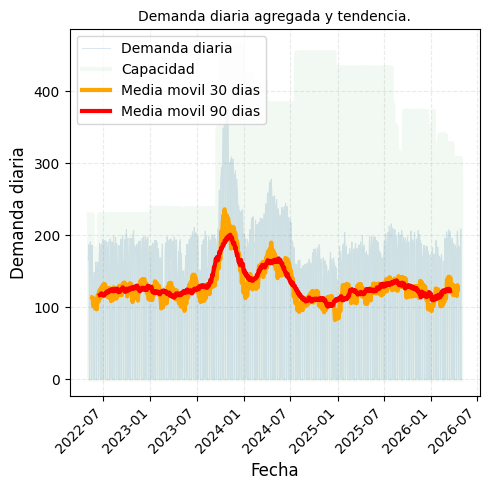

In [30]:
plt.figure(figsize = (5, 5))

plt.plot(
    demanda_diaria["ds"], 
    demanda_diaria["y"], 
    color = "steelblue",
    linewidth = 0.7, 
    alpha = 0.20, 
    label = "Demanda diaria"
)

plt.plot(
    demanda_diaria["ds"],
    demanda_diaria["capacidad"],
    color = "green",
    linewidth = 3,
    alpha = 0.05,
    label = "Capacidad"
)

plt.plot(
    demanda_diaria["ds"],
    demanda_diaria["media_30"],
    color = "orange",
    linewidth = 3,
    label = "Media movil 30 dias"
)

plt.plot(
    demanda_diaria["ds"],
    demanda_diaria["media_90"],
    color = "red",
    linewidth = 3,
    label = "Media movil 90 dias"
)

plt.title("Demanda diaria agregada y tendencia.", fontsize = 10)
plt.xlabel("Fecha",fontsize = 12)
plt.ylabel("Demanda diaria", fontsize = 12)

plt.xticks(rotation = 45, ha="right")

plt.grid(
    True,
    linestyle="--",
    alpha = 0.25
)

plt.legend(frameon = True)
plt.tight_layout()
plt.show()

# Global forecasting

In [31]:
df_produccion.groupby(["tipo_dia"])["y"].count()

tipo_dia
festivo           347
fin de semana    2670
laboral          6347
Name: y, dtype: int64

In [32]:
# crear dummy variables
demanda_diaria = pd.get_dummies(demanda_diaria,columns = ["tipo_dia"])
print(demanda_diaria)


             ds    y  capacidad  media_30  media_90  tipo_dia_festivo  \
0    2022-05-03  166        229       NaN       NaN             False   
1    2022-05-04  180        229       NaN       NaN             False   
2    2022-05-05  187        229       NaN       NaN             False   
3    2022-05-06  140        229       NaN       NaN             False   
4    2022-05-07    0          0       NaN       NaN             False   
...         ...  ...        ...       ...       ...               ...   
1455 2026-04-26    0          0       NaN       NaN             False   
1456 2026-04-27  200        307       NaN       NaN             False   
1457 2026-04-28  209        307       NaN       NaN             False   
1458 2026-04-29  197        307       NaN       NaN             False   
1459 2026-04-30    0          0       NaN       NaN              True   

      tipo_dia_fin de semana  tipo_dia_laboral  
0                      False              True  
1                      Fa

In [33]:
demanda_diaria.columns = ["ds", "y","capacidad", "media_30", "media_90", "festivo", "fin_de_semana", "laboral"]
print(demanda_diaria)

             ds    y  capacidad  media_30  media_90  festivo  fin_de_semana  \
0    2022-05-03  166        229       NaN       NaN    False          False   
1    2022-05-04  180        229       NaN       NaN    False          False   
2    2022-05-05  187        229       NaN       NaN    False          False   
3    2022-05-06  140        229       NaN       NaN    False          False   
4    2022-05-07    0          0       NaN       NaN    False           True   
...         ...  ...        ...       ...       ...      ...            ...   
1455 2026-04-26    0          0       NaN       NaN    False           True   
1456 2026-04-27  200        307       NaN       NaN    False          False   
1457 2026-04-28  209        307       NaN       NaN    False          False   
1458 2026-04-29  197        307       NaN       NaN    False          False   
1459 2026-04-30    0          0       NaN       NaN     True          False   

      laboral  
0        True  
1        True  
2  

In [34]:
dates = demanda_diaria["ds"].sort_values().unique()
train_end = len(dates)-60
validation_end = len(dates)-30

train_dates = dates[:train_end]
validation_dates = dates[train_end:validation_end]
test_dates = dates[validation_end:]

In [35]:
train = demanda_diaria[demanda_diaria["ds"].isin(train_dates)] [["ds","y","capacidad","festivo","fin_de_semana","laboral"]]
validation = demanda_diaria[demanda_diaria["ds"].isin(validation_dates)] [["ds","y","capacidad","festivo","fin_de_semana","laboral"]]
test = demanda_diaria[demanda_diaria["ds"].isin(test_dates)] [["ds","y","capacidad","festivo","fin_de_semana","laboral"]]

In [36]:
print(f"rows in train subset: {train.shape[0]}")
print(f"rows in validation subset: {validation.shape[0]}")
print(f"rows in test subset: {test.shape[0]}")


rows in train subset: 1400
rows in validation subset: 30
rows in test subset: 30


# Agregar regresores

In [37]:
# Initialize and fit Prophet model
regressors = [c for c in train.columns if c not in ["ds","y", "capacidad"]]
param_grid = {
    "changepoint_prior_scale": [0.01, 0.1, 0.5],
    "seasonality_prior_scale": [1,5,10]
}

train_total = train.groupby("ds")["y"].sum().reset_index()
validation_total = validation.groupby("ds")["y"].sum().reset_index()
train_regressors = train.groupby("ds")[regressors].mean().reset_index()
validation_regressors = validation.groupby("ds")[regressors].mean().reset_index()
train_total = train_total.merge(train_regressors, on = "ds")
validation_total = validation_total.merge(validation_regressors, on = "ds")
print(train_total.shape[0])
print(validation_total.shape[0])

1399
30


## Tunear el modelo - buscando los mejores parametros

In [38]:
best_params = None
best_rmse = np.inf

In [39]:
for cps,sps in product(
    param_grid["changepoint_prior_scale"], 
    param_grid["seasonality_prior_scale"]
):
    params = {
        "changepoint_prior_scale":cps,
        "seasonality_prior_scale":sps,
    }

    m = Prophet(
        weekly_seasonality = True,
        **params
    )

    for r in regressors:
        m.add_regressor(r)

    m.fit(train_total)

    forecast = m.predict(validation_total)

    pred = forecast["yhat"].values
    rmse = np.sqrt(mean_squared_error(validation_total["y"], pred))

    if rmse < best_rmse:
        best_rmse = rmse
        best_params = params

    
    

20:11:03.005 | INFO    | prophet - Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.

20:11:03.275 | INFO    | prophet - Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.

20:11:03.536 | INFO    | prophet - Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.

20:11:03.827 | INFO    | prophet - Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.

20:11:04.269 | INFO    | prophet - Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.

20:11:04.704 | INFO    | prophet - Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.

20:11:05.302 | INFO    | prophet - Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.

20:11:06.326 | INFO    | prophet - Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.

20:11:07.374 | INFO    | prophet - Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.

## Pronóstico global

In [40]:
m_global = Prophet(weekly_seasonality = True, **best_params)

In [41]:
for r in regressors:
    m_global.add_regressor(r)
m_global.fit(train_total)

20:11:34.982 | INFO    | prophet - Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.

In [42]:
train_full = demanda_diaria[demanda_diaria["ds"].isin(np.concatenate([train_dates, validation_dates]))] [["ds","y","capacidad","festivo","fin_de_semana","laboral"]]

In [43]:
print(train_full.head(5))
print(train_full.shape[0])


          ds    y  capacidad  festivo  fin_de_semana  laboral
0 2022-05-03  166        229    False          False     True
1 2022-05-04  180        229    False          False     True
2 2022-05-05  187        229    False          False     True
3 2022-05-06  140        229    False          False     True
4 2022-05-07    0          0    False           True    False
1430


In [44]:
pred_train_full = m_global.predict(train_full)
print(len(pred_train_full))
print(pred_train_full.head(5))

1430
          ds       trend  yhat_lower  yhat_upper  trend_lower  trend_upper  \
0 2022-05-03  120.870240  146.233596  204.957379   120.870240   120.870240   
1 2022-05-04  120.936461  147.139235  205.250712   120.936461   120.936461   
2 2022-05-05  121.002682  144.016151  203.300595   121.002682   121.002682   
3 2022-05-06  121.068903  136.995012  195.503429   121.068903   121.068903   
4 2022-05-07  121.135125  -46.922522   11.067709   121.135125   121.135125   

   additive_terms  additive_terms_lower  additive_terms_upper  \
0       53.754264             53.754264             53.754264   
1       55.256488             55.256488             55.256488   
2       52.865355             52.865355             52.865355   
3       44.609842             44.609842             44.609842   
4     -140.212046           -140.212046           -140.212046   

   extra_regressors_additive  ...     weekly  weekly_lower  weekly_upper  \
0                  37.643187  ...  16.935233     16.935233 

In [46]:
train_compare = train_full.merge(pred_train_full[["ds","yhat"]],
                               on = "ds",
                               how = "inner")
train_compare["yhat"] = train_compare["yhat"].clip(lower = 0)
train_compare["se"] =  (train_compare['y'] - train_compare['yhat'])**2
totaly = np.sum(np.abs(train_compare["y"]))
train_compare["wmape"] = np.abs(train_compare['y'] - train_compare['yhat'])
print(f"WMAPE = { 100 * np.sum(train_compare['wmape']) / totaly }")
print(f"Accuracy = {100-(100* train_compare['wmape'].sum()/totaly)}")

print(train_compare.head(5))
print(train_compare.shape[0])

WMAPE = 10.775677918678488
Accuracy = 89.22432208132152
          ds    y  capacidad  festivo  fin_de_semana  laboral        yhat  \
0 2022-05-03  166        229    False          False     True  174.624504   
1 2022-05-04  180        229    False          False     True  176.192949   
2 2022-05-05  187        229    False          False     True  173.868037   
3 2022-05-06  140        229    False          False     True  165.678745   
4 2022-05-07    0          0    False           True    False    0.000000   

           se      wmape  
0   74.382067   8.624504  
1   14.493639   3.807051  
2  172.448451  13.131963  
3  659.397956  25.678745  
4    0.000000   0.000000  
1432


In [47]:
pred_test = m_global.predict(test)
print(len(pred_test))
print(pred_test.head(5))

30
          ds       trend  yhat_lower  yhat_upper  trend_lower  trend_upper  \
0 2026-04-01  137.165365  167.121973  229.446719   137.165365   137.165365   
1 2026-04-02  137.174828  169.485486  227.972256   137.174828   137.174828   
2 2026-04-03  137.184291  -29.220504   28.064483   137.184291   137.184291   
3 2026-04-04  137.193754  -25.581629   33.904905   137.193754   137.193754   
4 2026-04-05  137.203217  -23.051870   36.851175   137.203217   137.203217   

   additive_terms  additive_terms_lower  additive_terms_upper  \
0       60.664388             60.664388             60.664388   
1       59.199194             59.199194             59.199194   
2     -136.644492           -136.644492           -136.644492   
3     -132.319358           -132.319358           -132.319358   
4     -131.533543           -131.533543           -131.533543   

   extra_regressors_additive  ...     weekly  weekly_lower  weekly_upper  \
0                  37.643187  ...  18.572056     18.572056   

In [48]:
test_compare = test.merge(pred_test[["ds","yhat"]],
                               on = "ds",
                               how = "inner")
test_compare["yhat"] = test_compare["yhat"].clip(lower = 0)
test_compare["se"] =  (test_compare['y'] - test_compare['yhat'])**2
totaly = np.sum(np.abs(test_compare["y"]))
test_compare["wmape"] = np.abs(test_compare['y'] - test_compare['yhat'])
print(f"WMAPE = { 100 * np.sum(test_compare['wmape']) / totaly }")
print(f"Accuracy = {100-(100* test_compare['wmape'].sum()/totaly)}")

print(test_compare.head(5))
print(test_compare.shape[0])

WMAPE = 8.658304060775494
Accuracy = 91.34169593922451
          ds    y  capacidad  festivo  fin_de_semana  laboral        yhat  \
0 2026-04-01  183        307    False          False     True  197.829753   
1 2026-04-02  161        307    False          False     True  196.374021   
2 2026-04-03    0          0     True          False    False    0.539799   
3 2026-04-04    0          0    False           True    False    4.874396   
4 2026-04-05    0          0    False           True    False    5.669674   

            se      wmape  
0   219.921573  14.829753  
1  1251.321391  35.374021  
2     0.291383   0.539799  
3    23.759741   4.874396  
4    32.145208   5.669674  
30


## Unir train and test subset con sus respectivos pronósticos

In [54]:
df_full = pd.concat([train_compare, test_compare], ignore_index = True)
df_full = df_full.sort_values("ds").reset_index(drop = True)
print(df_full.head(4))

          ds    y  capacidad  festivo  fin_de_semana  laboral        yhat  \
0 2022-05-03  166        229    False          False     True  174.624504   
1 2022-05-04  180        229    False          False     True  176.192949   
2 2022-05-05  187        229    False          False     True  173.868037   
3 2022-05-06  140        229    False          False     True  165.678745   

           se      wmape  
0   74.382067   8.624504  
1   14.493639   3.807051  
2  172.448451  13.131963  
3  659.397956  25.678745  


## Corrigiendo df_full forecast asignando la demanda 0 para dias no laborables.


In [99]:
df_full[df_full["laboral"]==False]["yhat"]=0
df_full["se"] = (df_full["y"]-df_full["yhat"]) **2
totaly = np.sum(np.abs(df_full["y"]))
df_full["wmape"] = np.abs(df_full['y'] - df_full['yhat'])/totaly


In [100]:
df = df_full [["ds", "y" ,"capacidad", "festivo", "fin_de_semana","laboral", "yhat"]]
print(df)

             ds    y  capacidad  festivo  fin_de_semana  laboral        yhat
0    2022-05-03  166        229    False          False     True  174.624504
1    2022-05-04  180        229    False          False     True  176.192949
2    2022-05-05  187        229    False          False     True  173.868037
3    2022-05-06  140        229    False          False     True  165.678745
4    2022-05-07    0          0    False           True    False    0.000000
...         ...  ...        ...      ...            ...      ...         ...
1457 2026-04-26    0          0    False           True    False    0.668660
1458 2026-04-27  200        307    False          False     True  189.983096
1459 2026-04-28  209        307    False          False     True  193.243476
1460 2026-04-29  197        307    False          False     True  194.298248
1461 2026-04-30    0          0     True          False    False    3.033898

[1462 rows x 7 columns]


In [101]:
df_full.to_csv(ROOT / "data" / "processed" / "wide_fc_global_tipo_dia.csv", index = False)

In [93]:
df_long = df.melt(
    id_vars = ["ds", "capacidad", "festivo", "fin_de_semana","laboral"],
    value_vars = ["y", "yhat"],
    var_name = "servicios",
    value_name = "valor"
)

In [59]:
df_long.to_csv(ROOT / "data"/ "processed" / "long_fc_global_tipo_dia.csv", index = False)

## Calcular la proporcion de servicios atendidos por equipo

In [60]:
print(demanda_diaria.head(4))

          ds    y  capacidad  media_30  media_90  festivo  fin_de_semana  \
0 2022-05-03  166        229       NaN       NaN    False          False   
1 2022-05-04  180        229       NaN       NaN    False          False   
2 2022-05-05  187        229       NaN       NaN    False          False   
3 2022-05-06  140        229       NaN       NaN    False          False   

   laboral  
0     True  
1     True  
2     True  
3     True  


## Calculando las proporciones

In [69]:
total_per_day = demanda_diaria[["ds","y"]]
total_per_day.columns = ["ds", "y_total"]
print(total_per_day.head(4))

          ds  y_total
0 2022-05-03      166
1 2022-05-04      180
2 2022-05-05      187
3 2022-05-06      140


In [80]:
print(total_per_day[total_per_day["y_total"]==0])

             ds  y_total
4    2022-05-07        0
5    2022-05-08        0
11   2022-05-14        0
12   2022-05-15        0
18   2022-05-21        0
...         ...      ...
1447 2026-04-18        0
1448 2026-04-19        0
1454 2026-04-25        0
1455 2026-04-26        0
1459 2026-04-30        0

[469 rows x 2 columns]


In [70]:
df_prop = df_produccion.merge(total_per_day, on = "ds")
print(df_prop.head(5))

          ds    equipo   y  capacidad tipo_dia novedad  y_total
0 2022-05-03   HALCYON  59         70  laboral     NaN      166
1 2022-05-03   SYNERGY  41         65  laboral     NaN      166
2 2022-05-03  SYNERGY2  32         47  laboral     NaN      166
3 2022-05-03  SYNERGY3  34         47  laboral     NaN      166
4 2022-05-04   HALCYON  64         70  laboral     NaN      180


In [83]:
df_prop["prop"] = np.where(df_prop["y_total"] > 0,  df_prop["y"] / df_prop["y_total"], 0 )

## Promediando las proporciones

In [84]:
weights = df_prop.groupby("equipo")["prop"].mean().reset_index()
print(weights.head(5))

       equipo      prop
0  EDGE1_6107  0.044325
1  EDGE2_6137  0.042768
2     HALCYON  0.159343
3    HALCYON3  0.119168
4    HALCYON4  0.127478


## asignacion del forecast local

In [85]:
print(demanda_diaria.columns)

Index(['ds', 'y', 'capacidad', 'media_30', 'media_90', 'festivo',
       'fin_de_semana', 'laboral'],
      dtype='object')


In [86]:
df_top_forecast = df_full.groupby("ds")["yhat"].sum().reset_index()
print(df_top_forecast.head(5))

          ds        yhat
0 2022-05-03  174.624504
1 2022-05-04  176.192949
2 2022-05-05  173.868037
3 2022-05-06  165.678745
4 2022-05-07    0.000000


In [87]:
df_top = df_top_forecast.copy()
df_top["key"] = 1
weights["key"] = 1

In [88]:
df_eq_forecast = df_top.merge(weights, on = "key").drop("key", axis =1)
df_eq_forecast["yhat_equipo"] = df_eq_forecast["yhat"] * df_eq_forecast["prop"]

In [89]:
print(df_eq_forecast.head(5))

          ds        yhat      equipo      prop  yhat_equipo
0 2022-05-03  174.624504  EDGE1_6107  0.044325     7.740279
1 2022-05-03  174.624504  EDGE2_6137  0.042768     7.468336
2 2022-05-03  174.624504     HALCYON  0.159343    27.825184
3 2022-05-03  174.624504    HALCYON3  0.119168    20.809579
4 2022-05-03  174.624504    HALCYON4  0.127478    22.260763
